# 02 · Training and evaluation

Trains the `ECG1DCNN` model (a 1D-CNN on the 12-lead signal plus a small MLP on the metadata) and evaluates it on the held-out test fold.

**Prerequisite:** run `python prepare_data.py` from the repo root to create `data/processed/data.npz` (features scaled and signals normalised with training-set statistics).

The same steps are available as scripts: `python train.py` and `python evaluate.py`.

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath(".."))  # make the `ptbxl` package importable

DATA_DIR = os.environ.get("PTBXL_DATA_DIR", "../data/ptb-xl")
NPZ_PATH = os.environ.get("PTBXL_NPZ", "../data/processed/data.npz")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim

from ptbxl.data import load_npz
from ptbxl.model import ECG1DCNN
from ptbxl.metrics import compute_metrics, per_label_report, format_metrics
from ptbxl.training import (set_seed, get_device, make_datasets, make_loaders,
                            train_model, plot_history, load_model, predict)

set_seed(42)
device = get_device()
EPOCHS = int(os.environ.get("PTBXL_EPOCHS", 10))
CHECKPOINT = os.environ.get("PTBXL_CHECKPOINT", "../checkpoints/ecg_best_model.pt")
os.makedirs(os.path.dirname(CHECKPOINT), exist_ok=True)

## 1. Load the prepared data

* `X`: 8 standardised tabular features
* `Y`: ECG signals, shape `(N, 1000, 12)`, z-normalised per lead
* `Z`: multi-hot targets over the 44 diagnostic statements

In [2]:
splits, label_names, feature_names = load_npz(NPZ_PATH)
for name, d in splits.items():
    print(f"{name:<6} X={d['X'].shape}  Y={d['Y'].shape}  Z={d['Z'].shape}")

datasets = make_datasets(splits)
loaders = make_loaders(datasets, batch_size=64)

train  X=(17441, 8)  Y=(17441, 1000, 12)  Z=(17441, 44)
valid  X=(2193, 8)  Y=(2193, 1000, 12)  Z=(2193, 44)
test   X=(2203, 8)  Y=(2203, 1000, 12)  Z=(2203, 44)


## 2. Model

```
ECG (12 x 1000)
  -> Conv1d(32, k=7) + BN + ReLU + MaxPool
  -> Conv1d(64, k=5) + BN + ReLU + MaxPool
  -> Conv1d(128, k=3) + BN + ReLU + GlobalAvgPool  --> 128 ┐
                                                           ├─ concat(160) -> Linear(64) -> ReLU -> Linear(44) -> Sigmoid
metadata (8) -> Linear(32) -> ReLU -> Linear(32)   -->  32 ┘
```

Loss: binary cross-entropy (one independent binary problem per label). Optimiser: Adam, lr = 1e-3, batch size 64.

In [3]:
num_features = splits["train"]["X"].shape[1]
num_labels = splits["train"]["Z"].shape[1]
model = ECG1DCNN(num_features=num_features, num_labels=num_labels)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

ECG1DCNN(
  (conv1): Conv1d(12, 32, kernel_size=(7,), stride=(1,), padding=(3,))
  (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (bn3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): AdaptiveAvgPool1d(output_size=1)
  (tabular_net): Sequential(
    (0): Linear(in_features=8, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
  )
  (classifier): Sequential(
    (0): Linear(in_features=160, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_

## 3. Training

The checkpoint with the lowest **validation** loss is kept. The test set is not used here at all; it is evaluated exactly once in section 4.

Training on cpu for 10 epochs


Epoch  1/10 | train loss 0.1351 | val loss 0.0833 | val macro AUROC 0.7856 | val macro F1 0.0333  <- saved


Epoch  2/10 | train loss 0.0753 | val loss 0.0762 | val macro AUROC 0.8235 | val macro F1 0.1068  <- saved


Epoch  3/10 | train loss 0.0683 | val loss 0.0685 | val macro AUROC 0.8460 | val macro F1 0.1168  <- saved


Epoch  4/10 | train loss 0.0641 | val loss 0.0693 | val macro AUROC 0.8631 | val macro F1 0.1262


Epoch  5/10 | train loss 0.0617 | val loss 0.0653 | val macro AUROC 0.8744 | val macro F1 0.1361  <- saved


Epoch  6/10 | train loss 0.0597 | val loss 0.0640 | val macro AUROC 0.8811 | val macro F1 0.1463  <- saved


Epoch  7/10 | train loss 0.0580 | val loss 0.0618 | val macro AUROC 0.8903 | val macro F1 0.1372  <- saved


Epoch  8/10 | train loss 0.0567 | val loss 0.0661 | val macro AUROC 0.8930 | val macro F1 0.1538


Epoch  9/10 | train loss 0.0558 | val loss 0.0608 | val macro AUROC 0.8967 | val macro F1 0.1517  <- saved


Epoch 10/10 | train loss 0.0549 | val loss 0.0603 | val macro AUROC 0.8987 | val macro F1 0.1788  <- saved


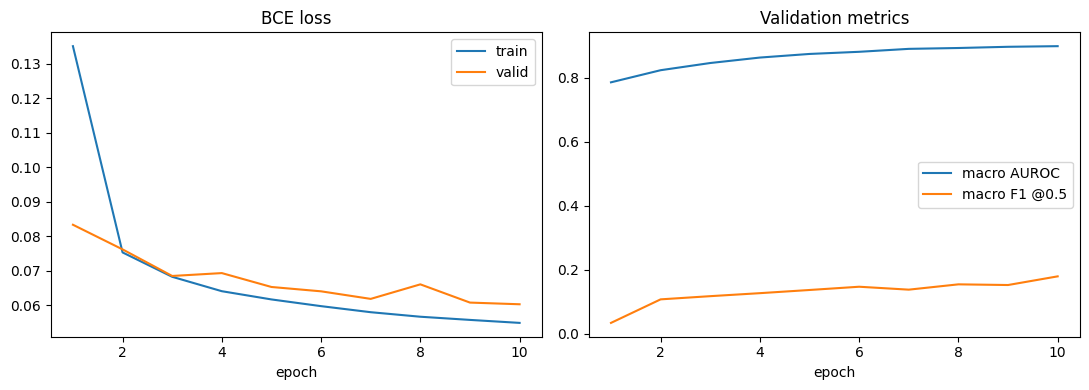

In [4]:
history = train_model(
    model, loaders,
    optimizer=optim.Adam(model.parameters(), lr=1e-3),
    criterion=nn.BCELoss(),
    epochs=EPOCHS,
    device=device,
    checkpoint_path=CHECKPOINT,
    extra_checkpoint_info={"num_features": num_features, "num_labels": num_labels,
                           "label_names": label_names, "feature_names": feature_names},
)
plot_history(history)
plt.show()

## 4. Test-set evaluation

### Why the original "accuracy" was misleading
The first version of this notebook reported `(preds == labels).sum() / labels.numel()` and got about 98%. That counts each of the 44 label cells of every record separately; since about 97% of those cells are 0, predicting "no diagnosis" for everyone already scores about 97%. It also evaluated the test set every epoch, which mixes the test set into model development.

### Metrics used instead
| Metric | What it tells you |
|---|---|
| **Macro AUROC** | Ranking quality per label, averaged equally over labels. Threshold-free. The standard PTB-XL benchmark metric. |
| Micro AUROC | Same, but pooled over all label cells (dominated by frequent labels). |
| Macro / micro average precision | Area under the precision-recall curve; much harsher than AUROC on rare labels. |
| Macro / micro / sample F1 @ 0.5 | Quality of the actual yes/no predictions. |
| Subset accuracy | Fraction of records whose *entire* label vector is exactly right. |
| Hamming loss | Fraction of wrong label cells (= 1 - label-wise accuracy). |

In [5]:
best_model, ckpt = load_model(CHECKPOINT, device)
print(f"Best checkpoint: epoch {ckpt['epoch'] + 1}, val loss {ckpt['val_loss']:.4f}\n")

y_true, y_prob = predict(best_model, loaders["test"], device)
test_metrics = compute_metrics(y_true, y_prob, threshold=0.5)
print(format_metrics(test_metrics))

Best checkpoint: epoch 10, val loss 0.0603



Macro AUROC                  0.9095
Micro AUROC                  0.9676
Macro avg. precision         0.2707
Micro avg. precision         0.7041
Macro F1                     0.1726
Micro F1                     0.6439
Sample-wise F1               0.6185
Subset (exact-match) acc.    0.5238
Hamming loss                 0.0195
Label-wise accuracy (old)    0.9805
  ...all-negative baseline   0.9681
(threshold=0.5, n=2203, AUROC over 44/44 labels)


Compare the last two lines: the old label-wise accuracy sits close to the trivial all-negative baseline, so on its own it says little about whether the model has learned anything. The threshold-free metrics above it are what to look at.

### Per-label results

In [6]:
report = per_label_report(y_true, y_prob, label_names, threshold=0.5)
report.round(3)

,support,auroc,average_precision,precision,recall,f1
label,,,,,,
NORM,964,0.944,0.917,0.772,0.956,0.854
IMI,268,0.944,0.745,0.760,0.567,0.650
ASMI,236,0.976,0.872,0.860,0.678,0.758
LVH,214,0.944,0.716,0.738,0.449,0.558
NDT,183,0.915,0.506,0.635,0.219,0.325
LAFB,163,0.982,0.857,0.858,0.669,0.752
ISC_,128,0.957,0.661,0.753,0.430,0.547
IRBBB,112,0.971,0.692,0.724,0.562,0.633
1AVB,80,0.818,0.131,0.000,0.000,0.000


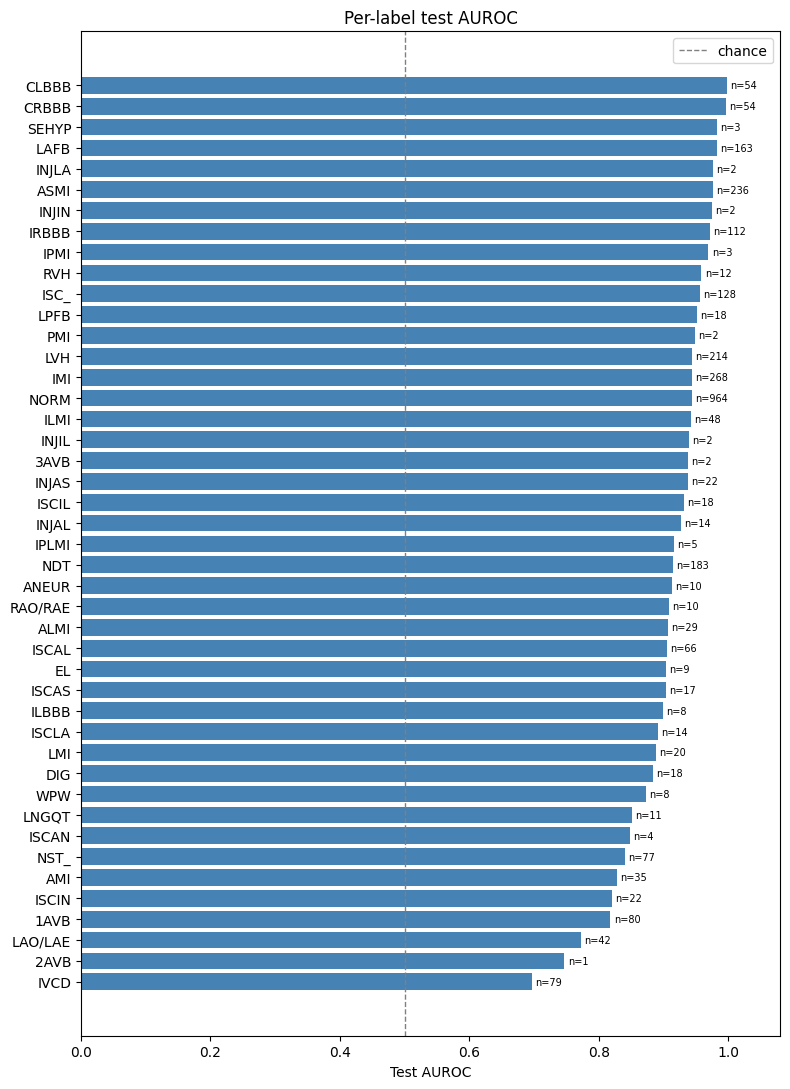

In [7]:
r = report.dropna(subset=["auroc"]).sort_values("auroc")
fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(r.index, r.auroc, color="steelblue")
ax.axvline(0.5, color="grey", linestyle="--", linewidth=1, label="chance")
ax.set_xlabel("Test AUROC")
ax.set_title("Per-label test AUROC")
for i, (lbl, row) in enumerate(r.iterrows()):
    ax.text(row.auroc + 0.005, i, f"n={int(row.support)}", va="center", fontsize=7)
ax.set_xlim(0, 1.08)
ax.legend()
plt.tight_layout()
plt.show()

## 5. Example prediction

One test record: the normalised 12-lead signal and the true vs. predicted diagnostic statements.

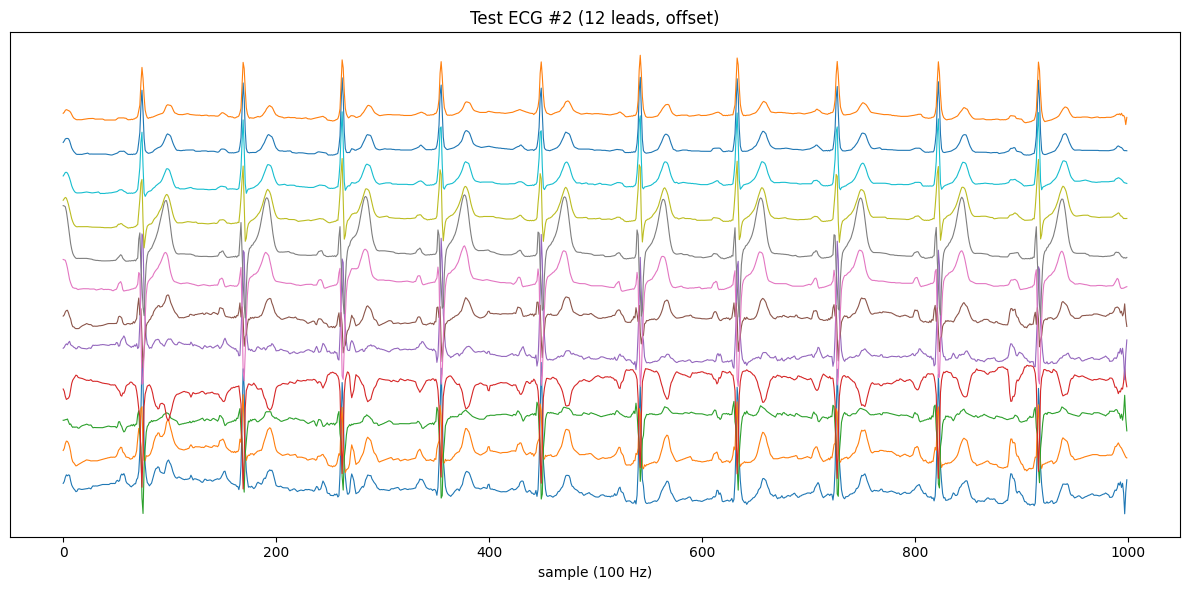

True labels     : ['NORM']
Predicted labels: ['NORM']
Top-5 by probability:
  NORM   0.960
  IVCD   0.045
  NDT    0.016
  1AVB   0.015
  LVH    0.011


In [8]:
sample_idx = 2
ecg_sample, tabular_sample, true_vec = datasets["test"][sample_idx]
probs = y_prob[sample_idx]

plt.figure(figsize=(12, 6))
for i in range(12):
    plt.plot(ecg_sample[:, i] + i * 2, linewidth=0.8)  # offset leads for readability
plt.title(f"Test ECG #{sample_idx} (12 leads, offset)")
plt.xlabel("sample (100 Hz)")
plt.yticks([])
plt.tight_layout()
plt.show()

true_labels = [label_names[j] for j in np.where(true_vec.numpy() == 1)[0]]
pred_labels = [label_names[j] for j in np.where(probs >= 0.5)[0]]
print("True labels     :", true_labels)
print("Predicted labels:", pred_labels)
print("Top-5 by probability:")
for j in np.argsort(probs)[::-1][:5]:
    print(f"  {label_names[j]:<6} {probs[j]:.3f}")